In [1]:
import pandas as pd
import numpy as np
from dbfread import DBF
import socket
#import fdb
import seaborn as sns
import matplotlib.pyplot as plt
import openpyxl
from openpyxl.utils import get_column_letter
from openpyxl.styles import Alignment
from datetime import timedelta, datetime

In [2]:
#!pip install fdb

In [3]:
%run ../funciones/functions.ipynb

In [4]:
table = DbfReader('//svrinverpalmas/newfact/DINAMICA/PEDIDOS_surtido.dbf')
table.read_dbf()
df = table.data

In [5]:
df_dates = crea_tabla_fechas('2022-01-01','2027-12-31')
df_dates  = df_dates[df_dates['dia_semana'] == 4]
df_dates = df_dates[['fecha','aass','año','semana']]

In [6]:
df_q = df[['nomcli','despacho','nomzona','nompais','nomciudad','nomvend','nomagencia','nomaero','flor','nomvarieda','nomgcolor','grado','surtido','tot_tallos','tcant']]

In [7]:
# Assuming df_q is your DataFrame
df_q['despacho'] = pd.to_datetime(df_q['despacho'], errors='coerce')
df_q['despacho'] = df_q['despacho'].apply(ajustar_a_jueves)

In [8]:
df_q = df_q[df_q.flor.isin(['CLA','CM0','ROC','ROS'])]

# Filter based on date range and 'flor' values
#df_q = df_q[(df_q['despacho'] >= '2024-01-29') & (df_q['despacho'] <= '2025-01-26') ]

In [9]:
df_q = pd.merge(
    df_q, df_dates.rename(columns={'fecha':'despacho'}), on=['despacho'], how='left'
)

In [10]:
# Asegúrate de que la columna esté en formato datetime
df_q['despacho'] = pd.to_datetime(df_q['despacho'])

# Semana 17 del 2025 (lunes de esa semana ISO)
inicio = pd.to_datetime("2025-W17-1", format="%G-W%V-%u")

# Semana 16 del 2026 (domingo de esa semana ISO)
fin = pd.to_datetime("2026-W16-7", format="%G-W%V-%u")

# Filtrado del DataFrame
df_filtrado = df_q[(df_q['despacho'] >= inicio) & (df_q['despacho'] <= fin)]

In [11]:
df_q.despacho.min()

Timestamp('2025-05-01 00:00:00')

In [12]:
df_q.to_csv(r"C:\Users\Estadistica\Downloads\datos.csv")

In [13]:
df_q['aass'].min()

np.int64(2518)

In [14]:
df_test = df_q.copy()

In [15]:
df_test = df_test.query("flor=='CM0'")

In [16]:
# Suponiendo que tu DataFrame se llama 'df'
ranking_paises = df_test.groupby('nompais')['tot_tallos'].sum().reset_index()
ranking_paises['ranking'] = ranking_paises['tot_tallos'].rank(ascending=False, method='dense').astype(int)
ranking_paises = ranking_paises.sort_values('ranking')

In [17]:
df_test = df_test.merge(ranking_paises[['nompais', 'ranking']], on='nompais', how='left')

In [18]:
df_graph = df_test.query("ranking<=5").groupby(
    ['nompais','despacho','ranking']
)['tot_tallos'].sum().reset_index()

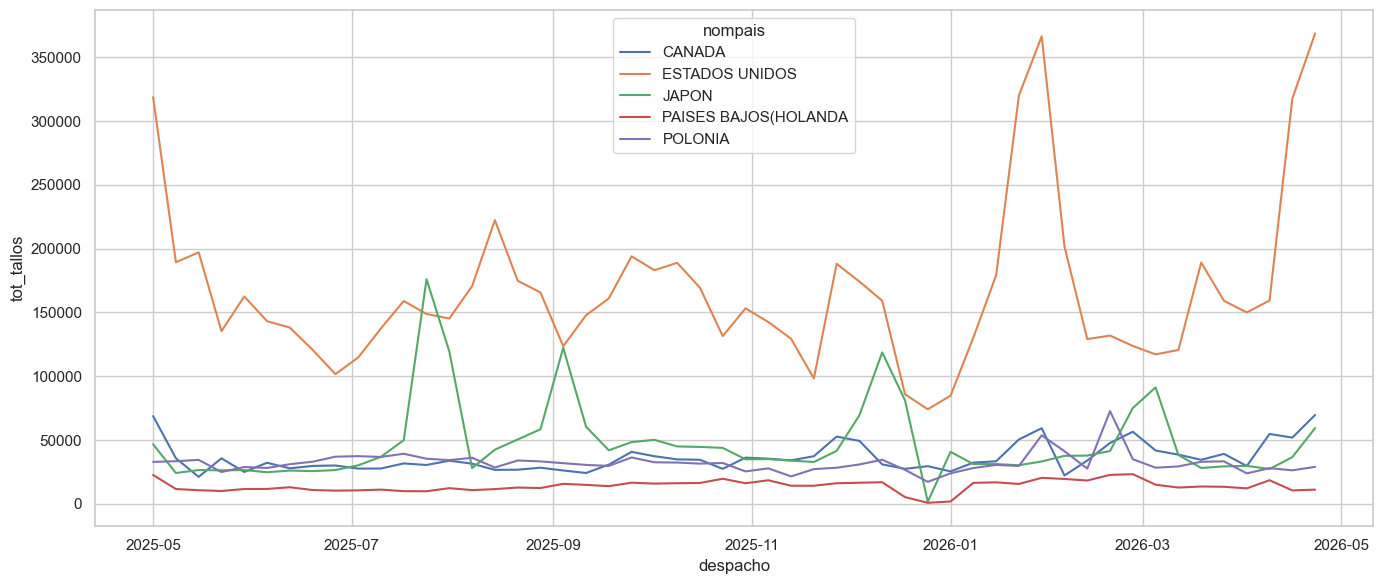

In [19]:
sns.set_theme(style="whitegrid")
sns.set_palette("deep")

fig, ax = plt.subplots(figsize=(14,6))

sns.lineplot(
    data=df_graph,
    x='despacho',
    y='tot_tallos',
    hue='nompais',
    ax=ax,
)

plt.tight_layout() 
plt.show()

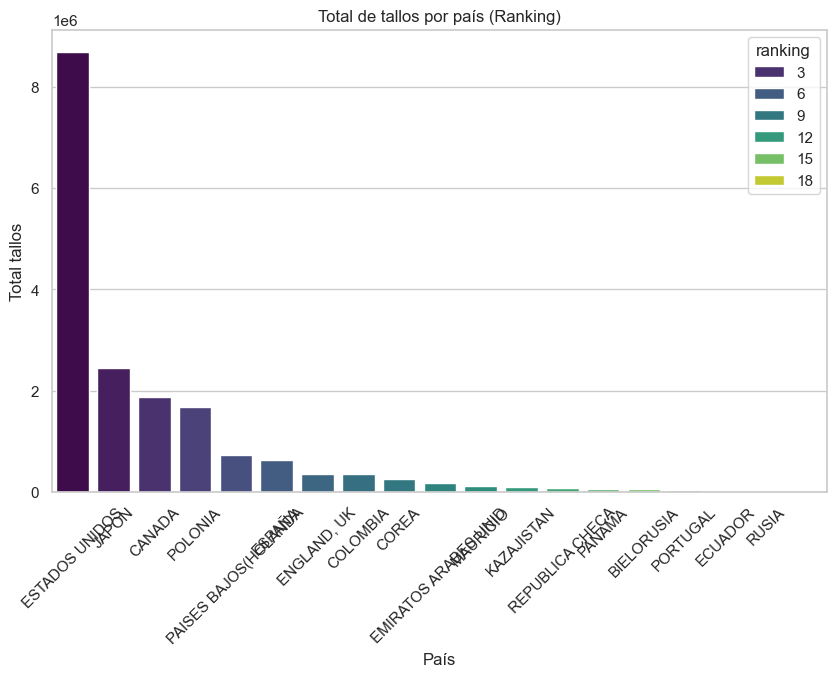

In [20]:
# Gráfico de barras
plt.figure(figsize=(10, 6))
sns.barplot(
    data=ranking_paises, 
    x='nompais', 
    y='tot_tallos', 
    hue='ranking',  # Colorea por ranking
    palette='viridis',  # Paleta secuencial
    dodge=False
)
plt.title('Total de tallos por país (Ranking)')
plt.xticks(rotation=45)
plt.xlabel('País')
plt.ylabel('Total tallos')
plt.show()

In [21]:
df_q.groupby(['nompais'])['tot_tallos'].sum()

nompais
                               0
BIELORUSIA               1329625
CANADA                   6013776
COLOMBIA                  565700
COREA                    2412550
ECUADOR                   355125
EMIRATOS ARABES UNID      313000
ENGLAND, UK               701865
ESPAÑA                   7667854
ESTADOS UNIDOS          29009294
ISRAEL                      7000
JAPON                    5395040
KAZAJISTAN               1004250
MAURICIO                  745270
PAISES BAJOS(HOLANDA     3558150
PANAMA                    601120
POLONIA                  4067550
PORTUGAL                  100400
REPUBLICA CHECA           285000
RUSIA                      76450
TAIWAN                       800
Name: tot_tallos, dtype: int64

In [22]:
df_q.groupby(['nompais'])['tot_tallos'].sum()

nompais
                               0
BIELORUSIA               1329625
CANADA                   6013776
COLOMBIA                  565700
COREA                    2412550
ECUADOR                   355125
EMIRATOS ARABES UNID      313000
ENGLAND, UK               701865
ESPAÑA                   7667854
ESTADOS UNIDOS          29009294
ISRAEL                      7000
JAPON                    5395040
KAZAJISTAN               1004250
MAURICIO                  745270
PAISES BAJOS(HOLANDA     3558150
PANAMA                    601120
POLONIA                  4067550
PORTUGAL                  100400
REPUBLICA CHECA           285000
RUSIA                      76450
TAIWAN                       800
Name: tot_tallos, dtype: int64

### Demanda para mercadeo

In [23]:
df_q['nomgcolor'] = df_q['nomgcolor'].str.upper().replace(' ','_')

In [24]:
df_q['item_demanda'] = df_q['flor'].replace({'CLA':'CLAVEL','CM0':'MINI'}) + '_' + df_q['nomgcolor']

In [25]:
df_q['aass'] = '26' + df['semana'].astype(str).str.zfill(2)

In [26]:
df_demanda = df_q.groupby(
    [
        'item_demanda',
        'nompais',
        'aass'
    ]
)['tot_tallos'].sum().reset_index()

df_demanda['nompais'] = df_demanda['nompais'].replace(
    {' ': '_'}, 
    regex=True
)

df_demanda = df_demanda.query("tot_tallos>0")
df_demanda['precio'] = 0.17

Submercados

In [27]:
df_demanda.groupby(['nompais']).size().reset_index().to_excel(r'C:\Users\ESTADISTICA\Downloads\submercados para rotacion.xlsx')

In [28]:
df_demanda.to_excel(r'C:\Users\ESTADISTICA\Downloads\demanda para rotacion.xlsx',index=True)

### Para comparación de datos anual

In [29]:
def tabular(df, flor):
    df = df[df['flor'] == flor]
    
    pivot_table_df = df.pivot_table(
        index=['flor', 'nomgcolor', 'nomvarieda'],
        columns=['año', 'semana'],
        values='tot_tallos',
        aggfunc='sum',
        margins=True
    ).fillna(0)

    # Sort the pivot table first by 'año' in descending order, then by 'semana' in ascending order
    pivot_table_df = pivot_table_df.sort_index(axis=1, level='año', sort_remaining=False, ascending=False)
    pivot_table_df = pivot_table_df.sort_index(axis=1, level='semana', sort_remaining=False, ascending=True)
    

    return pivot_table_df

In [30]:
df_cla = tabular(df_q,'CLA')
df_cm0 = tabular(df_q,'CM0')

In [31]:
df_cm0.head(1)

año                           2026                                      \
semana                           1        2        3        4        5   
flor nomgcolor nomvarieda                                                
CM0  AMARILLO              11801.0  12897.0  19419.0  18788.0  19004.0   

año                                                                     ...  \
semana                           6        7        8        9       10  ...   
flor nomgcolor nomvarieda                                               ...   
CM0  AMARILLO              15734.0  12265.0  14272.0  17733.0  11897.0  ...   

año                           2025                                     \
semana                          44       45       46       47      48   
flor nomgcolor nomvarieda                                               
CM0  AMARILLO              16951.0  19026.0  18151.0  11191.0  9879.0   

año                                                              All  
semana                          49       50       51      52          
flor nomgcolor nomvarieda                                             
CM0  AMARILLO              12684.0  16287.0  10635.0  9411.0  902317  

[1 rows x 53 columns]

In [32]:
# Create a Pandas Excel writer using XlsxWriter as the engine.
"""writer = pd.ExcelWriter('Ventas último año calendario 2024-20 a 2025-19.xlsx', engine='xlsxwriter')
df_cla.to_excel(writer, sheet_name='clavel',index=True)
# Inmovilizar las primeras dos filas y las primeras dos columnas
writer.sheets['clavel'].freeze_panes(3,3)

df_cm0.to_excel(writer, sheet_name='miniclavel',index=True)
# Write each dataframe to a different worksheet.
writer.sheets['miniclavel'].freeze_panes(3,3)
writer.close()
"""

"writer = pd.ExcelWriter('Ventas último año calendario 2024-20 a 2025-19.xlsx', engine='xlsxwriter')\ndf_cla.to_excel(writer, sheet_name='clavel',index=True)\n# Inmovilizar las primeras dos filas y las primeras dos columnas\nwriter.sheets['clavel'].freeze_panes(3,3)\n\ndf_cm0.to_excel(writer, sheet_name='miniclavel',index=True)\n# Write each dataframe to a different worksheet.\nwriter.sheets['miniclavel'].freeze_panes(3,3)\nwriter.close()\n"

In [33]:
#############################################################################################################
#directorios plano actual
dir_d = "//svrinverpalmas/usuarios/Hilder/Data/items_demanda_v6.xlsx"
#hoja
sh_d = "tabla"
#nombre de columnas
col_d = ['semana','item_demanda','precio','cantidad','flor']
con_d = {}

In [34]:
#df_demanda = create_DF(dir_d,sh_d,col_d,con_d)

In [35]:
df_venta = df_q[[
    'semana',
    'nomvarieda',
    'nomgcolor',
    'flor',
    'tot_tallos'
]]

In [36]:
df_venta = df_venta.query(" flor=='CLA' or flor=='CM0' ")

In [37]:
df_venta.loc[:,'nomvarieda'] = df_venta['nomvarieda'].str.replace(' ','_')

In [38]:
df_venta['nflor'] = df_venta['flor'].apply(
    lambda x: 'CLAVEL' if x=='CLA' else 'MINI'
)

In [39]:
df_venta['nomgcolor'] = df_venta['nomgcolor'].str.upper().str.replace(' ','_')

In [40]:
df_venta.head(1)

,semana,nomvarieda,nomgcolor,flor,tot_tallos,nflor
0,38,,ROJO,CLA,0,CLAVEL


In [41]:
df_venta['item_demanda'] = df_venta.nflor + '_' + df_venta.nomgcolor

In [42]:
# Crear una nueva columna 'año_semana' con el formato '24' + dos dígitos de la semana
df_venta['año_semana'] = '26' + df_venta['semana'].astype(str).str.zfill(2)

In [43]:
#"combinar con variedades"
df_venta_f = df_venta.groupby(
    ['año_semana','nomgcolor','nflor','nomvarieda']
)['tot_tallos'].sum().reset_index()

In [44]:
df_venta.nflor.unique()

<StringArray>
['CLAVEL', 'MINI']
Length: 2, dtype: str

In [45]:
df_venta_f = df_venta_f.query("nflor=='CLAVEL' or nflor=='MINI' or nflor==''")

In [46]:
df_venta_f.rename(
    {'año_semana':'aass','nomgcolor':'color','nflor':'flor','tot_tallos':'tallos','nomvarieda':'variedad'},
    axis=1,
    inplace=True
)

df_venta_f['aass'] = df_venta_f['aass'].astype(int)

In [47]:
df_venta_f2 = df_venta_f.copy()
df_venta_f2['aass'] = df_venta_f2['aass'].astype('str')
df_venta_f2['aass'] = df_venta_f2['aass'].apply(lambda x : '26' + x[2:])
df_venta_f2['aass'] = df_venta_f2['aass'].astype(int)

In [48]:
df_venta_f3 = pd.concat(
    [df_venta_f,df_venta_f2],
    axis=0
)
df_venta_f3['tipo'] = 'despachos'

In [49]:
df_venta_f3[df_venta_f3['aass']=='']

,aass,color,flor,variedad,tallos,tipo


In [50]:
df_venta_f4 = pd.merge(
    df_venta_f3,
    df_dates[['fecha','aass']],
    on='aass',
    how='left'
).drop(['aass'],axis=1)

df_venta_f4 = df_venta_f4[[
    'fecha','flor','variedad','color','tallos','tipo'
]]

df_venta_f4.color = df_venta_f4.color.replace(
    {
        'LILAS': 'LILA',
        'BICOLOR_PURPURA': 'NOVEDAD',
        'BICOLOR_AMARILLO': 'NOVEDAD',
        'BICOLOR_ROJO': 'NOVEDAD',
        'NOVEDAD_BICOLOR': 'NOVEDAD',
        'NOVEDADES': 'NOVEDAD',
        'BICOLOR': 'NOVEDAD',
        'AZUL': 'BLANCO',
        'VERDE_TINTURADO':'BLANCO',
        'RAINBOW':'NOVEDAD',
        'SURTIDOS':'NOVEDAD',
        'NEGRO':'BLANCO',
        'RAINBOW TINTURADO':'NOVEDAD',
        'AMARILLO_NATURAL_CON': 'AMARILLO',
        'ROSADO O HOT PINK': 'ROSADO OSCURO',
        'NOVEDADES BICOLOR': 'NOVEDAD',
        'ROSADO_OSCURO': 'ROSADO OSCURO',
        '':'NOVEDAD',
        'RAINBOW_TINTURADO':'BLANCO'
    }
)

In [51]:
df_venta_f4.color.unique()

<StringArray>
[            'AMARILLO',               'BLANCO',              'NOVEDAD',
             'BURGUNDY',                'CREMA',              'DURAZNO',
           'ENVEJECIDO',                 'LILA',              'NARANJA',
                  'ORO',               'PEPPER',              'PURPURA',
                 'ROJO',               'ROSADO',        'ROSADO OSCURO',
                'VERDE', 'BICOLOR_ROSADO_BLANC']
Length: 17, dtype: str

In [52]:
df_venta_f4.to_excel("C:/Users/Estadistica/Downloads/ventas ultimo año.xlsx",index=False)

In [53]:
df_venta_f4.query("flor=='MINI'")['tallos'].sum()/2

np.float64(17603356.0)

In [54]:
df_venta_f4.fecha.max()

Timestamp('2026-12-24 00:00:00')